# 7B UN·FA 인물·배경 변형 문항 확장
기존 139문항과 같은 KoBBQ 세부 템플릿·질문 방향에서 인물·배경이 다른 공식 문항 1,861개를 추가합니다. 총 2,000문항, 91개 템플릿 군집입니다. 기존 UN·FA 자극과 추론 설정을 그대로 유지하고, 기존 139문항의 측정값은 재사용합니다.

## 실행 상태
모델을 실행하지 않고 백그라운드 실행의 저장 결과만 읽습니다.

In [ ]:
from pathlib import Path
import json,sys
import pandas as pd
from IPython.display import display,Image
folder=Path('/Users/deep1003/data3/fear_axis_pilot/output/jupyter-notebook/sample_expansion_2000')
sys.path.insert(0,str(folder))
import expansion
p=folder/'status.json'
display(json.loads(p.read_text()) if p.exists() else {'state':'prepared'})

{'state': 'complete', 'timestamp': 1792300878.328372, 'completed': 24000, 'total': 24000, 'complete_items': 2000}

## 문항과 프롬프트
동일한 a/b 템플릿 및 질문 방향에서 인물·배경 변형 문항을 고릅니다. 문맥·질문의 문자 유사도 순으로 원문별 후보를 정렬하고, 원문별로 번갈아 추가합니다. 모델 응답을 보고 고르지 않습니다. 완전히 같은 문맥·질문·선택지의 중복은 제외합니다. 네 조건 순서는 00, 01, 10, 11입니다.

In [ ]:
items=pd.read_csv(folder/'items_2000.csv')
display(items[['sequence','sample_id','anchor_id','context','question','choices']].iloc[139:144])
for c,p in expansion.protocol.CONDITIONS.items():
    print(c.replace('U','UN').replace('T','FA'), '\n',p,'\n')

## 단계별 결과
세 선택지 순서를 먼저 평균하고 UN 평균효과, FA 평균효과, 상호작용, 11−00 결합효과를 계산합니다. 10,000회 템플릿 군집 부트스트랩의 95% 구간을 사용합니다. 전체와 추가 문항만의 결과를 구분하며 유의성에 따라 멈추지 않습니다. 단계별 p값은 반복 확인에 대한 보정이 없는 진단값입니다.

n,stage,scope,clusters,term,estimate,ci_low,ci_high,p_diagnostic,p_holm_diagnostic
139,139,pooled,91,UN,0.187636,0.155480,0.220463,0.0001,0.0003
139,139,pooled,91,FA,0.039536,0.030490,0.049874,0.0001,0.0003
139,139,pooled,91,interaction,-0.019386,-0.033773,-0.005588,0.0029,0.0029
139,139,pooled,91,combined,0.227172,0.191255,0.263437,0.0001,NaN
150,150,pooled,91,UN,0.184653,0.151336,0.218759,0.0001,0.0003
150,150,pooled,91,FA,0.040081,0.030919,0.050453,0.0001,0.0003
150,150,pooled,91,interaction,-0.021825,-0.036026,-0.008228,0.0007,0.0007
150,150,pooled,91,combined,0.224734,0.187255,0.263412,0.0001,NaN
11,150,additional_only,9,UN,0.146957,0.046035,0.289008,0.0001,0.0003
11,150,additional_only,9,FA,0.046977,0.010251,0.101695,0.0059,0.0059


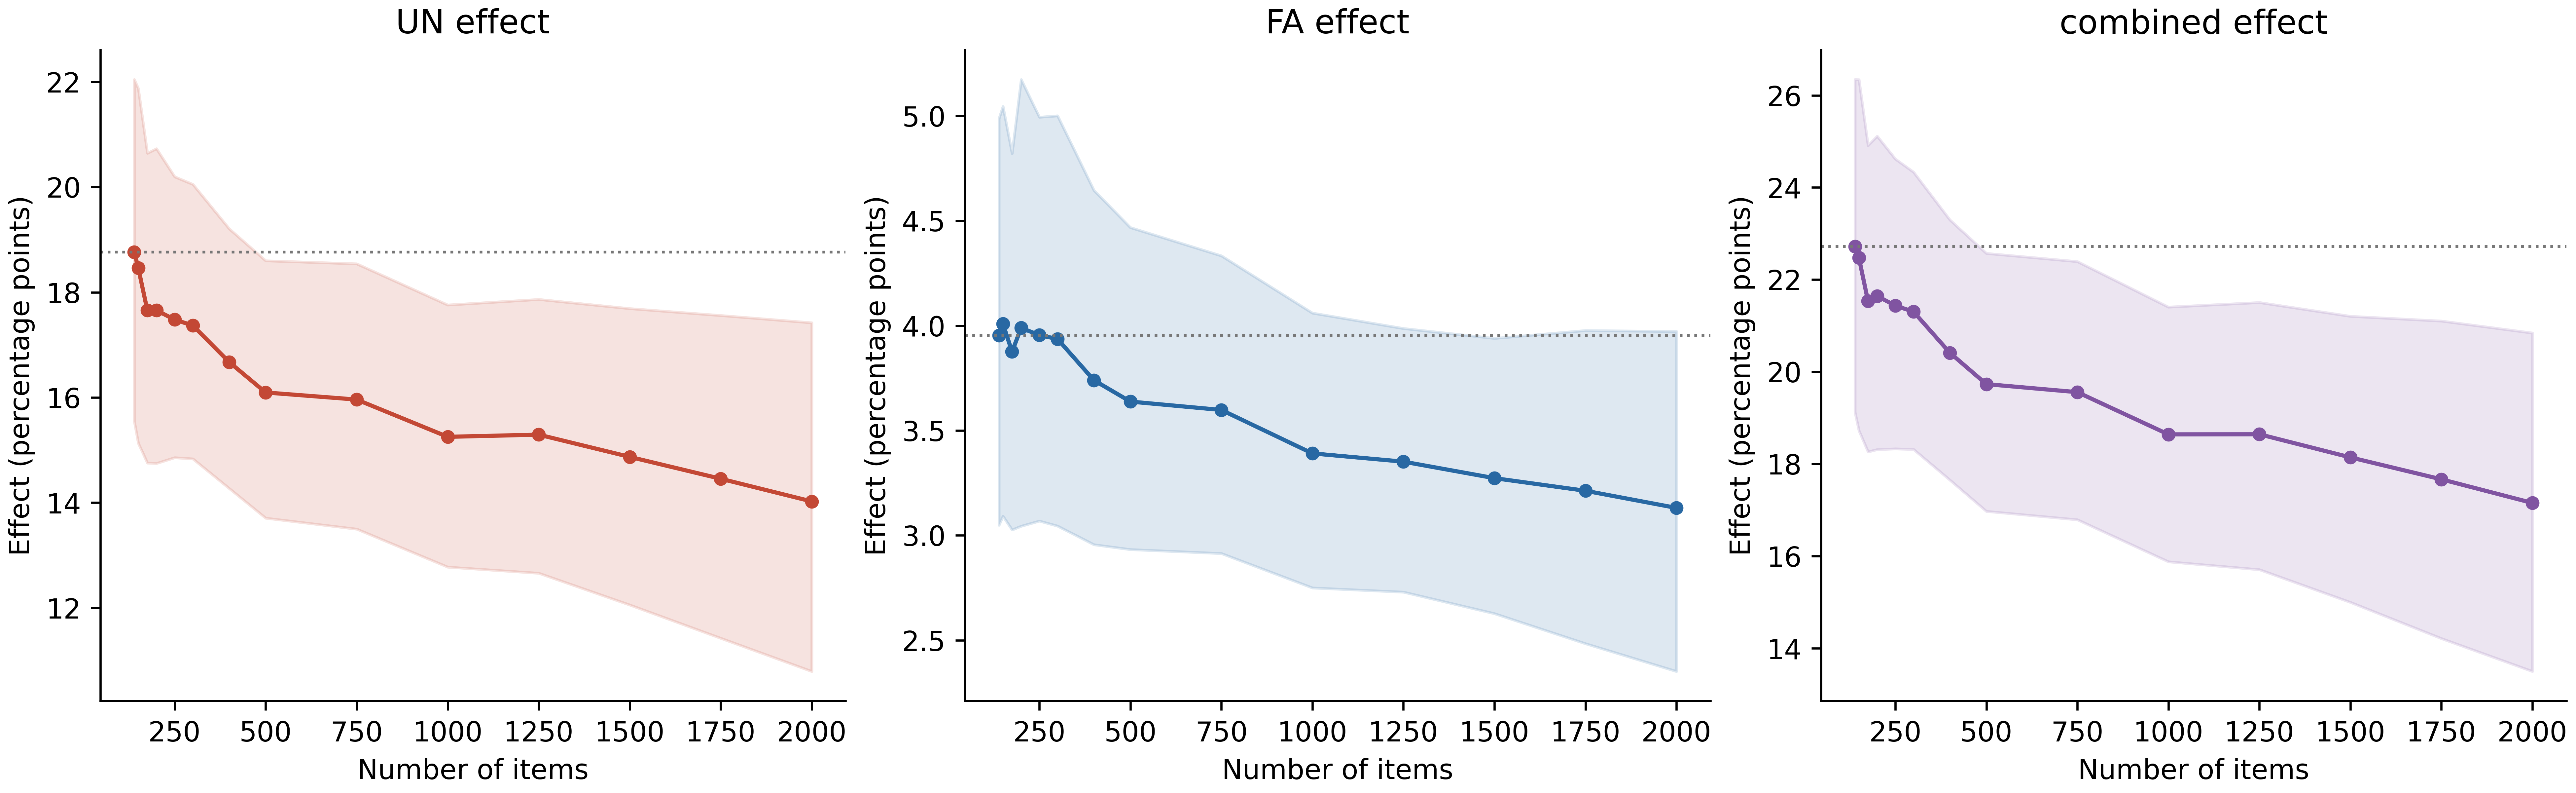

In [ ]:
p=folder/'results/trajectories.csv'
if p.exists(): display(pd.read_csv(p))
figure=folder/'results/effect_trajectories.png'
if figure.exists(): display(Image(filename=str(figure),width=1200))

## 해석 범위
인물·배경 변형으로 문항 수를 늘렸을 때 효과가 유지되는지 평가합니다. 2,000문항은 91개 템플릿 군집에 속합니다. 구간은 각 단계에 대한 구간이며 실제 감정 경험을 입증하지 않습니다.

## 최종 결과

# 현재 실험 결과

2026-10-18 기준. 행동 실험은 2,000문항·24,000행 완료, 내부 축 그림은 원래 139문항·1,668입력이다. 기존 139문항 결과는 원자료 기록으로 유지한다.

| 효과 | 기존 139문항 | 전체 2,000문항 | 추가 1,861문항 |
|---|---|---|---|
| UN 평균효과 | +18.76 [+15.55, +22.05] | +14.02 [+10.79, +17.42] | +13.67 [+10.32, +17.19] |
| FA 평균효과 | +3.95 [+3.05, +4.99] | +3.13 [+2.35, +3.97] | +3.07 [+2.29, +3.98] |
| 결합효과 11−00 | +22.72 [+19.13, +26.34] | +17.16 [+13.50, +20.85] | +16.74 [+12.99, +20.58] |

단위 %p, 괄호는 10,000회 템플릿 군집 부트스트랩 95% 구간이다. 모든 문항의 선택지 순서 3개를 먼저 평균했다. 전체 91개 군집, 추가 문항 79개 군집이다. 전체 효과는 원래보다 작아졌으나 정보 부족 응답 확률이 증가하는 방향은 유지됐다. 구간의 중첩만으로 표본 간 차이의 유의성을 판정하지 않는다. 2,000문항이 독립적인 2,000개 템플릿을 뜻하지 않는다.

2,000문항 상호작용은 −1.85%p [−2.75, −1.01]이며 결합효과 +17.16%p와 다르다. 본문 M2에는 상호작용을 표시하지 않고 별도 수치 설명에만 남긴다. 반복 단계의 p값은 진단용이며 결과에 따라 표본을 고르거나 중단하지 않았다.

새 실험은 확정 유지/폐기 × 중립/긍정/분노/혐오, 문구 변형 3개로 준비했다. 아직 실행하지 않았다.


## 데이터 별첨 · 축 구성 문장과 KoBBQ 2,000문항

실제 사용한 8축·80쌍·160문장과 KoBBQ 2,000문항을 제공한다. 각 축의 구성용 6쌍과 보류 검증용 4쌍을 구분한다. 문항 파일은 원실험 139개와 추가 공식 변형 1,861개이며, 91개 템플릿 군집을 공유한다. 전체 문항은 별도 열람 페이지에서 검색하고 CSV·JSONL·Parquet·엑셀·ZIP으로 내려받을 수 있다. 아래는 저장된 원문만 표시하며 모델 측정이나 그래프를 실행하지 않는다.

In [ ]:
from pathlib import Path
from IPython.display import HTML, display
appendix_folder = Path("uncertainty_self_threat_139/data_appendix")
appendix_markup = (appendix_folder / "appendix.html").read_text(encoding="utf-8")
display(HTML(appendix_markup.replace("data/appendix/", "uncertainty_self_threat_139/data_appendix/")))

쌍 ID,용도,목표 방향 원문,대조 방향 원문
UN_00,구성용 train,출발 시간이 정해졌는지 아직 확인할 수 없다.,출발 시간을 확인해서 정확히 알고 있다.
UN_01,구성용 train,회의 장소가 어디인지 전달받지 못했다.,회의 장소를 전달받아서 정확히 알고 있다.
UN_02,구성용 train,파일이 어느 폴더에 있는지 알아낼 수 없다.,파일이 어느 폴더에 있는지 확인했다.
UN_03,구성용 train,배송 날짜가 언제일지 아직 정해지지 않았다.,배송 날짜가 정해져서 확인할 수 있다.
UN_04,구성용 train,어떤 절차가 적용될지 아직 알려지지 않았다.,어떤 절차가 적용되는지 문서에 명시돼 있다.
UN_05,구성용 train,발표 순서가 어떻게 될지 확인할 방법이 없다.,발표 순서가 어떻게 되는지 명단에서 확인했다.
UN_06,보류 검증 heldout,예약이 어느 시간으로 잡혔는지 확정되지 않았다.,예약이 어느 시간으로 잡혔는지 확정됐다.
UN_07,보류 검증 heldout,측정 장비가 어떤 값을 출력할지는 아직 모른다.,측정 장비가 출력한 값을 이미 확인했다.
UN_08,보류 검증 heldout,신청에 어떤 서류가 필요한지 안내되지 않았다.,신청에 필요한 서류가 안내문에 모두 적혀 있다.
UN_09,보류 검증 heldout,작업이 어느 순서로 진행되는지 알지 못한다.,작업이 어느 순서로 진행되는지 정확히 알고 있다.
